<a href="https://colab.research.google.com/github/Najla-Nuricia/PemMes_244107020091_Najla/blob/main/JS11/JS11_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
from keras.src.legacy.preprocessing.image import ImageDataGenerator

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Errno 20] Not a directory: '/content/drive/MyDrive/dataset.zip'
/content


In [4]:
!unzip -q "/content/drive/MyDrive/dataset.zip" -d /content/
%cd /content

/content


In [5]:
	train_datagen = ImageDataGenerator(rescale = 1./255,
	                                   shear_range = 0.2,
	                                   zoom_range = 0.2,
	                                   horizontal_flip = True)
	training_set = train_datagen.flow_from_directory('dataset/training_set',
	                                                 target_size = (64, 64),
	                                                 batch_size = 32,
	                                                 class_mode = 'binary')

Found 8000 images belonging to 2 classes.


In [6]:
	test_datagen = ImageDataGenerator(rescale = 1./255)
	test_set = test_datagen.flow_from_directory('dataset/test_set',
	                                            target_size = (64, 64),
	                                            batch_size = 32,
	                                            class_mode = 'binary')

Found 2000 images belonging to 2 classes.


In [7]:
cnn = tf.keras.models.Sequential()

In [8]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

In [10]:
	cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
	cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

In [11]:
cnn.add(tf.keras.layers.Flatten())

In [12]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

In [13]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

In [14]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [15]:
cnn.fit(x = training_set, validation_data = test_set, epochs = 25)

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 73s 286ms/step - accuracy: 0.6204 - loss: 0.6517 - val_accuracy: 0.6250 - val_loss: 0.6423
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 71s 282ms/step - accuracy: 0.7090 - loss: 0.5662 - val_accuracy: 0.7155 - val_loss: 0.5574
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 68s 272ms/step - accuracy: 0.7259 - loss: 0.5352 - val_accuracy: 0.7360 - val_loss: 0.5350
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 70s 281ms/step - accuracy: 0.7605 - loss: 0.4958 - val_accuracy: 0.7575 - val_loss: 0.5137
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 68s 270ms/step - accuracy: 0.7782 - loss: 0.4664 - val_accuracy: 0.7870 - val_loss: 0.4696
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 71s 284ms/step - accuracy: 0.7849 - loss: 0.4578 - val_accuracy: 0.7715 - val_loss: 0.4774
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 74s 298ms/step - accuracy: 0.7944 - loss: 0.4368 - val_accuracy: 0.7935 - val_loss: 0.4470
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 69s 276ms/step - accuracy: 0.8049 - loss: 0

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


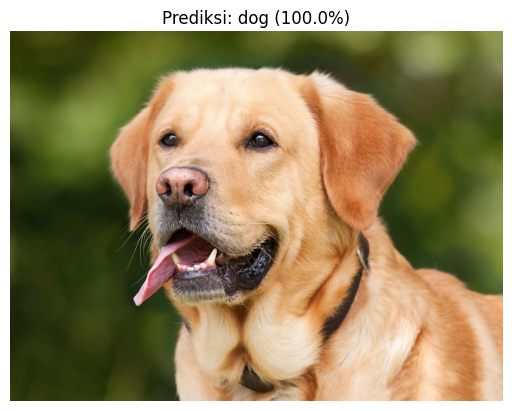

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

path = 'dataset/single_prediction/cat_or_dog_1.jpg'

img = load_img(path, target_size=(64, 64))
x = np.expand_dims(img_to_array(img), axis=0)

result = cnn.predict(x)
prob = result[0][0]
prediction = 'dog' if prob > 0.5 else 'cat'
confidence = prob if prob > 0.5 else 1 - prob

plt.imshow(load_img(path))  # gambar asli (bukan yang 64x64)
plt.title(f'Prediksi: {prediction} ({confidence*100:.1f}%)')
plt.axis('off')
plt.show()